# The math of network-spectral-predictor, walked through with the code

*Step 1 · pendulums on springs · built 2026-11-25 from the library at code version `6c136f0` by `tools/build_math_notebook.py`*

> **This notebook runs no Python, and it is not a source of truth.** Every code block is copied verbatim from `src/nsp` when the notebook is built, and every number in a worked example is computed by the library at that moment, so neither can drift from the code. The prose and the equations are hand-written: they explain the code, they do not define it. Where they disagree, the code and its tests win (the tests are listed at the end).

**How to read it.** Each part opens with one plain sentence, then the equations with every symbol defined, then a worked example, then the code that implements it. Parts 1 to 5 are the core (the world, the model, and what the model can and cannot represent); 6 and 7 are learning and measuring; 8 to 11 follow the experiments (large swings, detecting springs, recall, two angles); 12 opens step 2, where only angles are measured.

| Part | Topic | Experiments |
| --- | --- | --- |
| 0 | The picture | |
| 1 | One pendulum | E0 |
| 2 | Springs and the graph | E1–E3 |
| 3 | The whole world, and its modes | E0, E2 |
| 4 | The model: one body map, one spring map | E1–E3 |
| 5 | What one hop misses | E2 |
| 6 | Learning $K$ and $M$ | E1 |
| 7 | Measuring: actual, nominal, deviation | all |
| 8 | Large swings | E4 |
| 9 | Detecting the springs | E5 |
| 10 | Recall: structural and binding vertices | E6 |
| 11 | Preview of stage 1.5: two angles per body | stage 1.5 |
| 12 | Hidden information: a clamped sense | step 2, H1 |

## Notation

| Symbol | Meaning | In the code |
| --- | --- | --- |
| $n$; $v, u$ | number of bodies; body indices | `n`; `v`, `u` |
| $e=(u,v)$; $m$ | a spring between bodies $u$ and $v$; number of springs | `edges`; `len(edges)` |
| $d$ | position coordinates per body: 1 = one swing angle (planar), 2 = two tilts (stage 1.5) | `World.d` |
| $\theta_v$, $\dot\theta_v$ | swing angle of body $v$ (rad) and its rate (rad/s) | `X[..., 0::2]`, `X[..., 1::2]` |
| $x_v=(\theta_v,\dot\theta_v)$; $x$ | state of body $v$; all bodies stacked, $x=(x_1,\dots,x_n)$ | one row `X[traj, t]` |
| $t$ | sample index; one step is $\Delta t$ seconds | axis 1 of `X` |
| $\omega_0$ | a lone pendulum's frequency, $\sqrt{g/\ell}$ (rad/s) | `World.omega0` |
| $\kappa$ | spring stiffness ÷ inertia (1/s²) | `World.kappa` |
| $\Delta t$ | sampling step (s) | `World.dt` |
| $g_e\in\{0,1\}$ | gate of spring $e$: live or cut | `gates` |
| $\delta$ | incidence matrix, $m\times n$: row $e=(u,v)$ has $-1$ at $u$, $+1$ at $v$ | `graphs.incidence` |
| $L(g)$ | gated graph Laplacian, $n\times n$ | `graphs.laplacian` |
| $\lambda_k$, $u_k$ | graph frequencies (eigenvalues of $L$) and their patterns (eigenvectors) | `graphs.graph_frequencies` |
| $A_0$, $E$ | a lone body's generator; the $2\times2$ matrix that turns a position into an acceleration | `World.A0`, `World.E` |
| $A$ | the whole world's generator, $2n\times2n$ | `world.generator` |
| $K$, $M$ | the model's body map and spring map, $2\times2$ each | `OneHop.K`, `OneHop.M` |
| $K_0$, $M_0$, $N_0$ | the exact step's expansion in $\lambda$: order 0, 1 and 2 | `model.series`, `model.series_closed_form` |
| $P(g)$ | the assembled model step $I_n\otimes K-L(g)\otimes M$ | `OneHop.assemble` |
| $s_v$ | spring input of body $v$: $\sum_u g_{uv}(x_v-x_u)$ | `fit.body_samples` |
| $\psi$, $W$ | a body lift (features for large swings) and its learned read-out | `lifts.features`, `LiftedOneHop.W` |
| $G$, $\pi$, $T$, $h$, $\Sigma$ | stored gate patterns, belief over them, persistence matrix, hazard, residual covariance | `context` |
| $\otimes$ | Kronecker product: $A\otimes B$ puts a copy of $B$, scaled by $a_{ij}$, in block $(i,j)$ | `np.kron` |
| actual, nominal | the generated world, the model's prediction; deviation = actual − nominal | `metrics`, `viz` |

## 0 · The picture

*In one sentence:* a row of pendulums joined by springs is predicted with one small map for a pendulum and one small map for a spring, copied over the graph of springs.

In 1665 Huygens noticed that two pendulum clocks hanging from the same beam end up swinging in lockstep, in opposite directions: each clock is a lone oscillator, and the beam couples them (Bennett, Schatz, Rockwood & Wiesenfeld, *Proc. R. Soc. A* 2002, reconstruct the experiment). Here each pendulum is a lone oscillator, each spring a coupling, and a graph says which couplings exist. The bet of step 1 is that you can learn the lone oscillator ($K$) and the coupling ($M$) once, then assemble them for any graph, including graphs and switch patterns never seen in training.

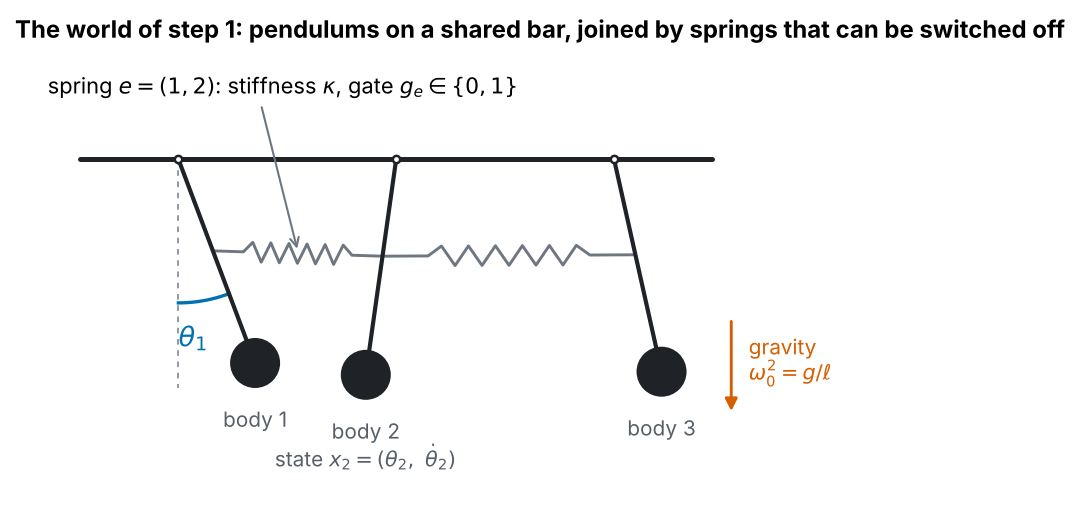

Everything that follows is about three questions: what the exact answer is (Parts 1 to 3), what the model can represent of it (4 and 5), and how the model is learned and judged (6 and 7).

## 1 · One pendulum

*In one sentence:* for small swings a lone pendulum is a two-number linear system, and its exact one-step map is a rotation in the $(\theta,\ \dot\theta/\omega_0)$ plane.

For small swings $\sin\theta\approx\theta$, so $\ddot\theta=-\omega_0^2\theta$. As a first-order system:

$$\frac{d}{dt}\underbrace{\begin{bmatrix}\theta\\ \dot\theta\end{bmatrix}}_{x_v}=\underbrace{\begin{bmatrix}0 & 1\\ -\omega_0^2 & 0\end{bmatrix}}_{A_0}\begin{bmatrix}\theta\\ \dot\theta\end{bmatrix}\qquad\Longrightarrow\qquad x_v(t+1)=\underbrace{e^{A_0\Delta t}}_{K_0}\,x_v(t)$$

The exponential has a closed form (sum the series, or check that it solves the equation):

$$K_0=\begin{bmatrix}\cos\omega_0\Delta t & \tfrac{1}{\omega_0}\sin\omega_0\Delta t\\ -\omega_0\sin\omega_0\Delta t & \cos\omega_0\Delta t\end{bmatrix},\qquad \operatorname{spec}K_0=\{e^{\pm i\omega_0\Delta t}\}$$

Its eigenvalues have modulus 1 (the swing neither grows nor decays) and angle $\omega_0\Delta t$: the phase advance per step. Every later "frequency" is read the same way, as (angle of an eigenvalue) ÷ $\Delta t$.

**Worked example** ($\omega_0=2$ rad/s, $\Delta t=0.05$ s, so $\omega_0\Delta t=0.1$ rad per step):

$$K_0=\begin{bmatrix}0.995 & 0.049917\\ -0.19967 & 0.995\end{bmatrix}$$

**In the library**, `src/nsp/world.py`: `World` (lines 24–49).

```python
@dataclass(frozen=True)
class World:
    """Physical constants. omega0 in rad/s, kappa in 1/s^2 (stiffness / inertia), dt in s."""

    omega0: float = 2.0
    kappa: float = 1.0
    dt: float = 0.05
    d: int = 1

    @property
    def A0(self) -> np.ndarray:
        """One body's generator, A0 (x) I_d."""
        return np.kron(np.array([[0.0, 1.0], [-self.omega0**2, 0.0]]), np.eye(self.d))

    @property
    def E(self) -> np.ndarray:
        """Routes a position into an acceleration: E (x) I_d."""
        return np.kron(np.array([[0.0, 0.0], [1.0, 0.0]]), np.eye(self.d))

    @property
    def body_size(self) -> int:
        """Numbers per body: 2d."""
        return 2 * self.d

    def with_(self, **changes) -> "World":
        return replace(self, **changes)
```

## 2 · Springs and the graph

*In one sentence:* the graph Laplacian turns "who is joined to whom" into a matrix whose row $v$ adds up the stretch of every live spring on body $v$.

The incidence matrix $\delta$ reads the stretch of each spring; the gates switch springs on and off; the Laplacian sums them back onto bodies:

$$\underbrace{(\delta\theta)_e}_{\text{stretch of spring }e=(u,v)}=\theta_v-\theta_u,\qquad L(g)=\delta^\top\operatorname{diag}(g)\,\delta=\sum_e g_e\,\underbrace{b_eb_e^\top}_{\text{spring }e\text{'s own Laplacian}},\qquad (L\theta)_v=\sum_u g_{uv}\,(\theta_v-\theta_u)$$

where $b_e^\top$ is row $e$ of $\delta$. $L$ is symmetric, its rows sum to zero ($L\mathbf 1=0$: moving every body together stretches nothing), and $\theta^\top L\theta=\sum_e g_e(\theta_v-\theta_u)^2\ge 0$, so its eigenvalues $\lambda_k$ are real and non-negative. They are the **graph frequencies**: how much each pattern of motion stretches the springs.

**Worked example: a path of 3** (springs 1–2 and 2–3, both live):

$$\delta=\begin{bmatrix}-1 & 1 & 0\\ 0 & -1 & 1\end{bmatrix},\qquad L=\delta^\top\delta=\begin{bmatrix}1 & -1 & 0\\ -1 & 2 & -1\\ 0 & -1 & 1\end{bmatrix},\qquad \lambda=0, 1, 3$$

Cut spring 1–2 ($g=(0,1)$) and body 1 hangs free: $L=\begin{bmatrix}0 & 0 & 0\\ 0 & 1 & -1\\ 0 & -1 & 1\end{bmatrix}$, with $\lambda=0, 0, 2$. A star of 8 has graph frequencies $\{0, 1, 8\}$; a complete graph of 8 only $\{0, 8\}$. Their largest value, 8, is far above anything in a path or ring of 3 or 5, which is what E2 tests.

**In the library**, `src/nsp/graphs.py`: `incidence` (lines 44–49), `laplacian` (lines 52–56), `graph_frequencies` (lines 59–61), `all_gate_patterns` (lines 64–66).

```python
def incidence(n: int, edges: list[Edge]) -> np.ndarray:
    """The incidence matrix delta (springs x bodies)."""
    D = np.zeros((len(edges), n))
    for e, (u, v) in enumerate(edges):
        D[e, u], D[e, v] = -1.0, 1.0
    return D

def laplacian(n: int, edges: list[Edge], gates=None) -> np.ndarray:
    """The gated graph Laplacian L(g) = delta^T diag(g) delta."""
    D = incidence(n, edges)
    g = np.ones(len(edges)) if gates is None else np.asarray(gates, float)
    return D.T @ (g[:, None] * D)

def graph_frequencies(n: int, edges: list[Edge], gates=None) -> np.ndarray:
    """The eigenvalues lambda_k of L(g), in ascending order (graph frequencies)."""
    return np.clip(np.linalg.eigvalsh(laplacian(n, edges, gates)), 0.0, None)

def all_gate_patterns(m: int) -> np.ndarray:
    """Every on/off pattern of m springs, shape (2^m, m); row k is the binary expansion of k."""
    return np.array([[(k >> i) & 1 for i in range(m)] for k in range(2**m)], float)
```

## 3 · The whole world, and its modes

*In one sentence:* stacked together the bodies form one linear system, and in the graph's own coordinates it falls apart into one lone pendulum per graph frequency, stiffened by $\kappa\lambda$.

Each body feels gravity and its springs: $\ddot\theta_v=-\omega_0^2\theta_v-\kappa\,(L\theta)_v$. The matrix $E=\begin{bmatrix}0&0\\1&0\end{bmatrix}$ routes a position into an acceleration, so in state form:

$$\dot x=\underbrace{\Big(\underbrace{I_n\otimes A_0}_{\text{each body alone}}\;-\;\underbrace{\kappa\,L(g)\otimes E}_{\text{springs}}\Big)}_{A}\,x,\qquad\text{e.g. path of 3: }A=\begin{bmatrix}A_0-\kappa E & \kappa E & 0\\ \kappa E & A_0-2\kappa E & \kappa E\\ 0 & \kappa E & A_0-\kappa E\end{bmatrix}$$

**Modes.** Diagonalise the graph, $L=U\Lambda U^\top$ with orthonormal $U=[u_1\ \cdots\ u_n]$. The Kronecker mixed-product rule $(A\otimes B)(C\otimes D)=AC\otimes BD$ gives

$$(U\otimes I_2)^\top A\,(U\otimes I_2)=\underbrace{U^\top U}_{I}\otimes A_0-\kappa\,\underbrace{U^\top LU}_{\Lambda}\otimes E=\operatorname{blockdiag}_k\big(\underbrace{A_0-\kappa\lambda_kE}_{\text{a lone pendulum with }\omega_0^2\to\omega_0^2+\kappa\lambda_k}\big)$$

$$\Longrightarrow\qquad\omega_k=\sqrt{\omega_0^2+\kappa\lambda_k}$$

So a network of $n$ pendulums is $n$ independent pendulums in disguise, one per pattern $u_k$, each as stiff as its pattern stretches the springs. The exact step is $e^{A\Delta t}$, block-diagonal in the same basis.

**Worked example** (path of 3, $\omega_0=2$, $\kappa=1$): $\lambda=0, 1, 3$ gives $\omega=2.0000, 2.2361, 2.6458$ rad/s, i.e. $2$, $\sqrt5$ and $\sqrt7$.

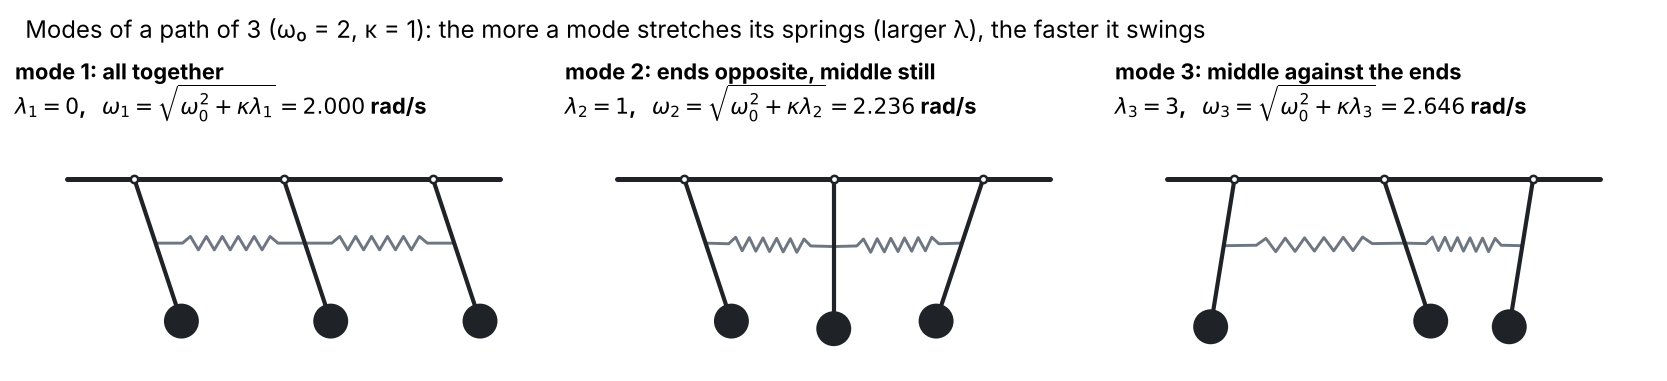

**In the library**, `src/nsp/world.py`: `generator` (lines 52–55), `exact_step` (lines 58–60), `mode_frequencies` (lines 63–66).

```python
def generator(world: World, L: np.ndarray) -> np.ndarray:
    """A = I_n (x) A0 - kappa L (x) E."""
    n = L.shape[0]
    return np.kron(np.eye(n), world.A0) - world.kappa * np.kron(L, world.E)

def exact_step(world: World, L: np.ndarray) -> np.ndarray:
    """The exact small-swing step e^{A dt}."""
    return expm(generator(world, L) * world.dt)

def mode_frequencies(world: World, L: np.ndarray) -> np.ndarray:
    """omega_k = sqrt(omega0^2 + kappa lambda_k) for each graph frequency lambda_k of L."""
    lam = np.clip(np.linalg.eigvalsh(L), 0.0, None)
    return np.sqrt(world.omega0**2 + world.kappa * lam)
```

## 4 · The model: one body map, one spring map

*In one sentence:* the model copies one learned body map $K$ onto every body and one learned spring map $M$ onto every live spring, so its size never depends on the graph.

$$\underbrace{x_v(t+1)}_{\text{next state of }v}=\underbrace{K\,x_v(t)}_{\text{body alone}}\;-\;\underbrace{M}_{\text{spring map}}\;\underbrace{\sum_u g_{uv}\big(x_v(t)-x_u(t)\big)}_{s_v(t)\text{: spring input}}\qquad\Longleftrightarrow\qquad x(t+1)=\underbrace{\big(I_n\otimes K-L(g)\otimes M\big)}_{P(g)}\,x(t)$$

$K$ and $M$ are $2\times2$: eight numbers in all, whatever the graph. For a path of 3, $P$ has the same block pattern as $A$:

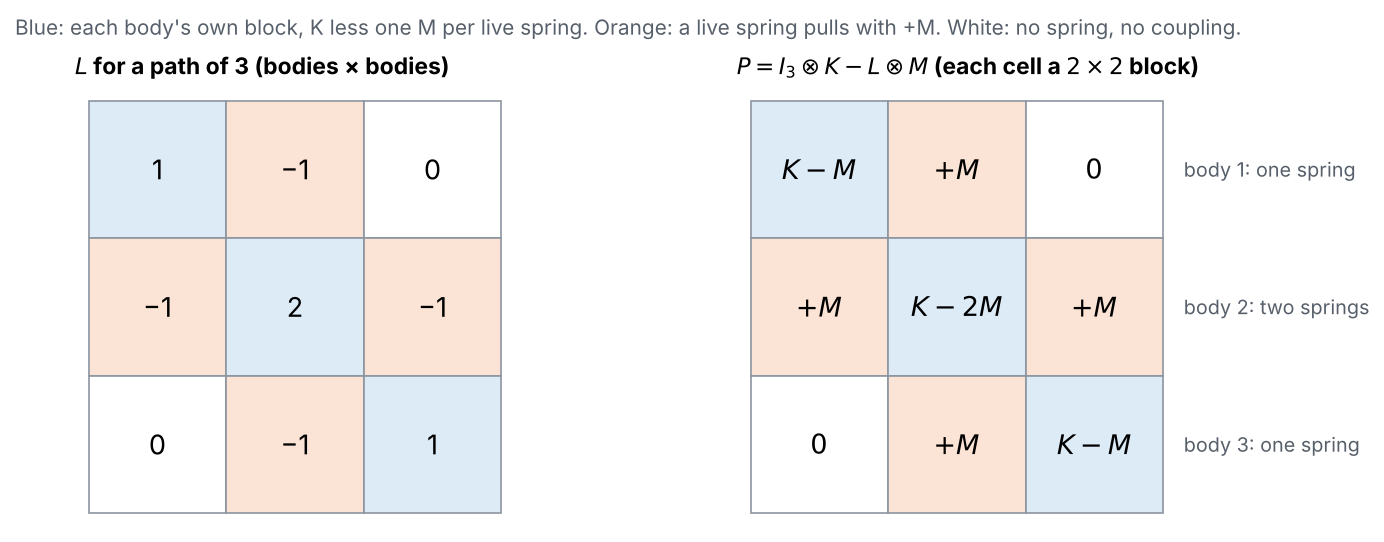

**The spectrum identity.** The argument of Part 3 applies word for word, with $K$ in place of $A_0$ and $M$ in place of $\kappa E$:

$$\operatorname{spec}P(g)=\bigcup_k\operatorname{spec}\big(\underbrace{K-\lambda_kM}_{2\times2,\text{ one per graph frequency}}\big)$$

So the model meets a graph only through its frequencies $\lambda_k$: two graphs with the same $\lambda$'s pose it the same per-mode problems. That is why transfer (E2) should follow $\lambda$, not the number of bodies, and why a model only has to be right over the range of $\lambda$ it will meet.

**In the plan's flat-model language**, $P=\operatorname{blockdiag}(K)+C\,\Gamma\,F$ with restriction map $F=\delta\otimes I_2$ (read the difference across each spring), gated edge map $\Gamma=\operatorname{diag}(g)\otimes M$, and write-back $C=-\delta^\top\otimes I_2$. Check: $C\Gamma F=-(\delta^\top\operatorname{diag}(g)\,\delta)\otimes M=-L(g)\otimes M$.

**In the library**, `src/nsp/model.py`: `OneHop` (lines 28–79).

```python
@dataclass
class OneHop:
    """Shared body map K and spring map M, each 2d x 2d."""

    K: np.ndarray
    M: np.ndarray

    def assemble(self, L: np.ndarray) -> np.ndarray:
        """The whole network's step: I_n (x) K - L (x) M."""
        n = L.shape[0]
        return np.kron(np.eye(n), self.K) - np.kron(L, self.M)

    def mode_block(self, lam: float) -> np.ndarray:
        """The step of one graph mode: K - lambda M."""
        return self.K - lam * self.M

    def spectrum(self, L: np.ndarray):
        """Graph frequencies of L and, for each, the eigenvalues of K - lambda M."""
        lams = np.clip(np.linalg.eigvalsh(L), 0.0, None)
        return lams, [np.linalg.eigvals(self.mode_block(lam)) for lam in lams]

    def mode_frequencies(self, lams, dt: float):
        """Frequency (|arg mu| / dt) and per-step modulus |mu| the model plays at each graph frequency."""
        w, r = [], []
        for lam in np.atleast_1d(lams):
            mu = np.linalg.eigvals(self.mode_block(lam))
            w.append(np.abs(np.angle(mu)).max() / dt)
            r.append(np.abs(mu).max())
        return np.array(w), np.array(r)

    def predict(self, X: np.ndarray, L: np.ndarray) -> np.ndarray:
        """One-step predictions of X[:, 1:] from X[:, :-1]."""
        return X[:, :-1] @ self.assemble(L).T

    def rollout(self, x0: np.ndarray, schedule: Schedule) -> np.ndarray:
        """Free-running prediction from x0 under a schedule of (steps, L) segments."""
        x0 = np.atleast_2d(x0)
        T = sum(steps for steps, _ in schedule)
        X = np.empty((x0.shape[0], T + 1, x0.shape[1]))
        X[:, 0] = x0
        t = 0
        for steps, L in schedule:
            P = self.assemble(L)
            for _ in range(steps):
                X[:, t + 1] = X[:, t] @ P.T
                t += 1
        return X

    def per_direction(self, d: int) -> "OneHop":
        """Apply a planar model once per direction: K (x) I_d, M (x) I_d (stage 1.5a)."""
        I = np.eye(d)
        return OneHop(np.kron(self.K, I), np.kron(self.M, I))
```

## 5 · What the exact answer is, and what one hop misses

*In one sentence:* expanding the exact step in $\lambda$ shows that the best one-hop model is the first two terms of a series, and the first term it cannot represent reaches two springs away, with relative size $\kappa\lambda\Delta t^2/6$.

The exact step of mode $k$ is $e^{(A_0-\kappa\lambda_kE)\Delta t}$. Expand it in $\lambda$:

$$e^{(A_0-\kappa\lambda E)\Delta t}=\underbrace{K_0}_{e^{A_0\Delta t}}\;-\;\lambda\,\underbrace{M_0}_{\text{first order}}\;+\;\lambda^2\,\underbrace{N_0}_{\text{second order}}\;-\;\cdots$$

Since $\lambda_k^j$ in every mode is $L^j$ on the whole graph, the exact step is $I\otimes K_0-L\otimes M_0+L^2\otimes N_0-\cdots$. The model represents the first two terms exactly. $L^2$ acts on each body, on its neighbours and on bodies two springs apart: a fitted model can soak up part of the first two, but nothing one-hop can reach the third. For an interior body of a path, $L^2$ has $6$ on the diagonal, $-4$ to each neighbour and $1$ two springs away.

$M_0$ is a directional derivative of the matrix exponential (a Fréchet derivative), which the library computes exactly: $M_0=\mathcal D\exp(A_0\Delta t)\,[\kappa E\Delta t]$. Expanded in $\Delta t$:

$$M_0=\kappa\begin{bmatrix}\tfrac{\Delta t^2}{2} & \tfrac{\Delta t^3}{6}\\[2pt] \Delta t-\tfrac{\omega_0^2\Delta t^3}{3} & \tfrac{\Delta t^2}{2}\end{bmatrix}+O(\Delta t^4),\qquad N_0=\kappa^2\begin{bmatrix}\tfrac{\Delta t^4}{24} & 0\\[2pt] \tfrac{\Delta t^3}{6} & \tfrac{\Delta t^4}{24}\end{bmatrix}+O(\Delta t^5)$$

Read the entries physically: a spring's pull first changes the *rate* (entry 2,1, size $\kappa\Delta t$) and only then the *angle* (entry 1,1, size $\kappa\Delta t^2/2$).

Three consequences, from the dominant entries (the ones in row 2, column 1):

$$\underbrace{\frac{\|\lambda^2N_0\|}{\|\lambda M_0\|}\approx\frac{\kappa\lambda\,\Delta t^2}{6}}_{\text{size of the two-hop miss}},\qquad\underbrace{|\mu|-1\approx\frac{(\kappa\lambda)^2\Delta t^4}{24}}_{\text{growth per step of }K_0-\lambda M_0},\qquad\underbrace{\frac{\hat\omega-\omega}{\omega}\approx\frac{(\kappa\lambda\Delta t)^2}{12\,\omega^2}}_{\text{frequency error}}$$

with $\mu$ an eigenvalue of $K_0-\lambda M_0$ and $\hat\omega=|\arg\mu|/\Delta t$.

**Worked example** ($\omega_0=2$, $\kappa=1$, $\Delta t=0.05$):

$$M_0=\begin{bmatrix}0.001248 & 2.08\times10^{-5}\\ 0.04983 & 0.001248\end{bmatrix},\qquad\text{closed form above}=\begin{bmatrix}0.00125 & 2.08\times10^{-5}\\ 0.04983 & 0.00125\end{bmatrix}\quad(\text{differ by }2.1 × 10⁻⁶),\qquad N_0\approx\begin{bmatrix}2.6\times10^{-7} & 0\\ 2.1\times10^{-5} & 2.6\times10^{-7}\end{bmatrix}$$

For a path of 3 ($\lambda\le3$) the two-hop miss is only 0.00125 of the one-hop term. For a star of 8 ($\lambda=8$) at $\kappa=16$ it is 0.0533; the series model also grows by 0.00427 per step (×2.34 over 200 steps, 10 s) and plays that mode 2.6% fast. These are the *series* model's numbers; a fitted model trades them off against each other, which E2 measures.

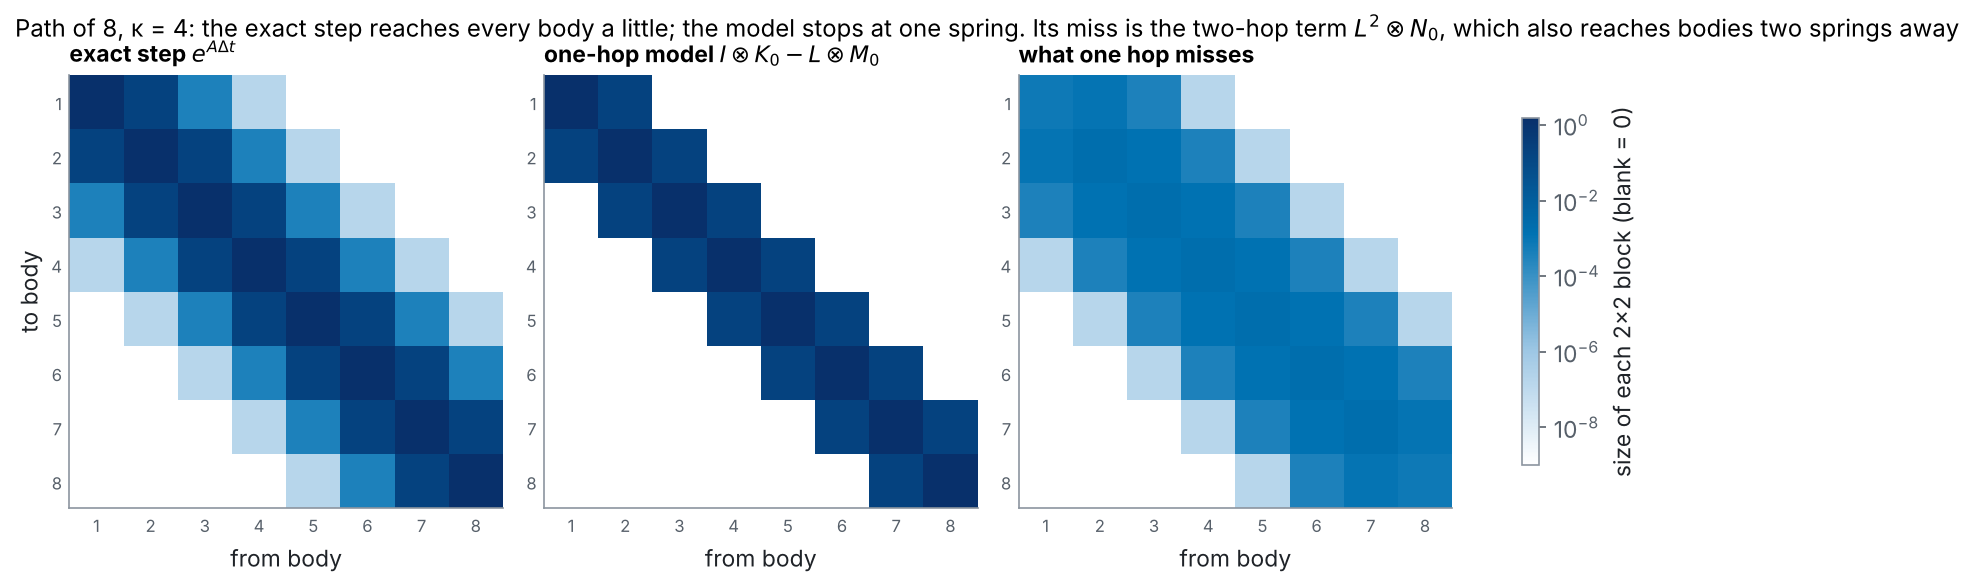

**In the library**, `src/nsp/model.py`: `series` (lines 82–87), `series_closed_form` (lines 90–96), `two_hop_ratio` (lines 99–101), `predicted_growth` (lines 104–106), `predicted_frequency_error` (lines 109–112).

```python
def series(world: World) -> OneHop:
    """The one-hop series: K0 = e^{A0 dt} and M0 = the first-order coefficient in lambda (a Frechet derivative)."""
    B = world.A0 * world.dt
    K0 = expm(B)
    M0 = expm_frechet(B, world.kappa * world.E * world.dt)[1]
    return OneHop(K0, M0)

def series_closed_form(world: World):
    """Closed forms from the plan: M0 to O(dt^3) and N0 to O(dt^4), each lifted by (x) I_d."""
    k, dt, w2 = world.kappa, world.dt, world.omega0**2
    M0 = k * np.array([[dt**2 / 2, dt**3 / 6], [dt - w2 * dt**3 / 3, dt**2 / 2]])
    N0 = k**2 * np.array([[dt**4 / 24, 0.0], [dt**3 / 6, dt**4 / 24]])
    I = np.eye(world.d)
    return np.kron(M0, I), np.kron(N0, I)

def two_hop_ratio(world: World, lam):
    """Size of the missed two-hop term relative to one hop: kappa lambda dt^2 / 6."""
    return world.kappa * np.asarray(lam) * world.dt**2 / 6

def predicted_growth(world: World, lam):
    """Per-step growth of the one-hop series at graph frequency lambda: (kappa lambda)^2 dt^4 / 24."""
    return (world.kappa * np.asarray(lam)) ** 2 * world.dt**4 / 24

def predicted_frequency_error(world: World, lam):
    """Relative frequency error of the one-hop series: (kappa lambda dt)^2 / (12 omega^2)."""
    lam = np.asarray(lam)
    return (world.kappa * lam * world.dt) ** 2 / (12 * (world.omega0**2 + world.kappa * lam))
```

## 6 · Learning $K$ and $M$

*In one sentence:* every body at every step is one sample of the same small regression, so $K$ and $M$ come from a single least-squares solve whose size does not grow with the graph.

Each sample $i$ is one (configuration, trajectory, step, body):

$$\underbrace{y_i}_{x_v(t+1)}=\underbrace{\begin{bmatrix}K & -M\end{bmatrix}}_{W^\top,\ 2\times4}\;\underbrace{\begin{bmatrix}x_v(t)\\ s_v(t)\end{bmatrix}}_{\varphi_i,\ 4\times1},\qquad s_v(t)=\big[(L(g)\otimes I_2)\,x(t)\big]_v$$

Least squares minimises $\mathcal E(W)=\frac1N\sum_i\|y_i-W^\top\varphi_i\|^2$. Setting its gradient to zero gives the normal equations:

$$W^{*\top}=\Big(\underbrace{\sum_i y_i\varphi_i^\top}_{2\times4}\Big)\Big(\underbrace{\sum_i\varphi_i\varphi_i^\top}_{4\times4}\Big)^{-1}$$

A $4\times4$ solve, for three bodies or three thousand. On clean small-swing data the answer is the series $(K_0,M_0)$ of Part 5, up to the small two-hop term the model cannot hold.

**Gradient descent on the same energy is local.** With each body's own error $\varepsilon_i=y_i-(Kx_v-Ms_v)$:

$$\Delta K\;\propto\;+\sum_i\varepsilon_i\,x_v^\top,\qquad\Delta M\;\propto\;-\sum_i\varepsilon_i\,s_v^\top$$

Each body needs only its own error and its own inputs: a delta rule. With step $\eta=1/\lambda_{\max}(H)$, $H=\frac1N\sum_i\varphi_i\varphi_i^\top$, it converges to $W^*$ (E1 checks this).

**Reading the physics back.** Since $K_0=e^{A_0\Delta t}$, the matrix logarithm returns $A_0$, and the $(2,1)$ entry of $M_0$ carries $\kappa$:

$$\hat\omega_0^2=-\Big[\tfrac{1}{\Delta t}\log K\Big]_{21},\qquad\hat\kappa=\frac{M_{21}}{\Delta t-\hat\omega_0^2\Delta t^3/3}$$

**Worked example**, applied to the exact series $(K_0,M_0)$: $\hat\omega_0^2=4.000000$ and $\hat\kappa=1.000003$. Without the $\Delta t^3$ correction, $M_{21}/\Delta t=0.996669$: 0.33% low.

**In the library**, `src/nsp/fit.py`: `body_samples` (lines 24–28), `fit_joint` (lines 41–47), `fit_frozen` (lines 50–56), `gradient_descent` (lines 80–103), `recover_parameters` (lines 106–113).

```python
def body_samples(X: np.ndarray, L: np.ndarray, d: int = 1):
    """Per-body samples x_v(t), s_v(t) and y_v = x_v(t+1), each of shape (N, 2d)."""
    D = 2 * d
    S = X @ np.kron(L, np.eye(D)).T
    return X[:, :-1].reshape(-1, D), S[:, :-1].reshape(-1, D), X[:, 1:].reshape(-1, D)

def fit_joint(datasets: list[Dataset], d: int = 1):
    """K and M together, by one least-squares solve. Returns (OneHop, info)."""
    x, s, y = _stack(datasets, d)
    P = np.hstack([x, s])
    W = np.linalg.lstsq(P, y, rcond=None)[0]
    D = 2 * d
    return OneHop(W[:D].T, -W[D:].T), {"samples": len(P), "condition": _condition(P)}

def fit_frozen(lone_X: np.ndarray, datasets: list[Dataset], d: int = 1) -> OneHop:
    """Decision 3's cross-check: K from lone bodies, then M on coupled data with K held fixed."""
    D = 2 * d
    K = np.linalg.lstsq(lone_X[:, :-1].reshape(-1, D), lone_X[:, 1:].reshape(-1, D), rcond=None)[0].T
    x, s, y = _stack(datasets, d)
    M = -np.linalg.lstsq(s, y - x @ K.T, rcond=None)[0].T
    return OneHop(K, M)

def gradient_descent(datasets: list[Dataset], d: int = 1, tol: float = 1e-6, max_iter: int = 200_000):
    """Plain gradient descent from zero, step 1/lambda_max; records the distance to the closed form."""
    x, s, y = _stack(datasets, d)
    P = np.hstack([x, s])
    N = len(P)
    H, b = P.T @ P / N, P.T @ y / N
    W_star = np.linalg.solve(H, b)
    eta = 1.0 / np.linalg.eigvalsh(H).max()
    W = np.zeros_like(W_star)
    norm = np.linalg.norm(W_star)
    marks = set(np.unique(np.geomspace(1, max_iter, 200).astype(int)))
    its, dist = [0], [1.0]
    it = 0
    for it in range(1, max_iter + 1):
        W -= eta * (H @ W - b)
        err = np.linalg.norm(W - W_star) / norm
        if it in marks or err < tol:
            its.append(it)
            dist.append(err)
        if err < tol:
            break
    D = 2 * d
    return OneHop(W[:D].T, -W[D:].T), {"iterations": it, "iters": np.array(its), "distance": np.array(dist),
                                        "condition": _condition(P)}

def recover_parameters(model: OneHop, world: World) -> dict:
    """Read the physics back: omega0^2 = -[log(K) / dt]_21, kappa = M_21 / (dt - omega0^2 dt^3 / 3)."""
    d = model.K.shape[0] // 2
    G = np.real(logm(model.K)) / world.dt
    w2 = -G[d, 0]
    return {"omega0_sq": float(w2),
            "kappa": float(model.M[d, 0] / (world.dt - w2 * world.dt**3 / 3)),
            "kappa_bare": float(model.M[d, 0] / world.dt)}
```

## 7 · Measuring: actual, nominal, deviation

*In one sentence:* the generated world is **actual**, the model's prediction **nominal**, and every result is a deviation judged against a tolerance, as on an inspection report.

This inverts the usual metrology roles on purpose. On a shop floor the nominal is the design and the actual is the part that was made; here the world is generated exactly, so it plays the measured part, and the prediction plays the design that the part is checked against.

$$\text{deviation}(t)=x^{\text{actual}}(t)-x^{\text{nominal}}(t),\qquad e(t)=\frac{\big\|X^{\text{nominal}}(t)-X^{\text{actual}}(t)\big\|}{\big\|X^{\text{actual}}(t)\big\|}$$

with norms over every trajectory and body at step $t$ (a free-running rollout from the same start). **Status:** *in* when $|\text{deviation}|\le\text{tolerance}$, *near* within twice it, *out* beyond.

For detection (Part 9) the score is the **AUROC**: the chance that a live spring scores above a missing one, ties counting half, computed from ranks (the Mann–Whitney statistic).

**In the library**, `src/nsp/metrics.py`: `relative` (lines 16–18), `rollout_curve` (lines 26–30), `status` (lines 60–63), `auroc` (lines 52–57).

```python
def relative(pred: np.ndarray, true: np.ndarray) -> float:
    """||pred - true|| / ||true|| over everything given."""
    return float(np.linalg.norm(pred - true) / np.linalg.norm(true))

def rollout_curve(X_actual: np.ndarray, X_nominal: np.ndarray) -> np.ndarray:
    """Relative error at each step of a free-running rollout, pooled over trajectories."""
    num = np.linalg.norm(X_nominal - X_actual, axis=(0, 2))
    den = np.linalg.norm(X_actual, axis=(0, 2))
    return num / den

def status(deviation: float, tolerance: float) -> str:
    """Inspection status: 'in' within tolerance, 'near' within twice it, else 'out'."""
    a = abs(deviation)
    return "in" if a <= tolerance else ("near" if a <= 2 * tolerance else "out")

def auroc(scores, labels) -> float:
    """Area under the ROC curve: chance a true spring outscores a missing one (ties count half)."""
    scores, labels = np.asarray(scores, float), np.asarray(labels).astype(bool)
    ranks = rankdata(scores)
    npos, nneg = labels.sum(), (~labels).sum()
    return float((ranks[labels].sum() - npos * (npos + 1) / 2) / (npos * nneg))
```

## 8 · Large swings: when $\sin\theta\neq\theta$

*In one sentence:* a wide swing is slower than a narrow one, which no fixed linear map can reproduce, so each body's map gets extra features (a lift) while the springs stay linear.

The world is now $\ddot\theta_v=-\omega_0^2\sin\theta_v-\kappa(L\theta)_v$. A lone pendulum released from angle $a$ swings at

$$\omega(a)=\frac{\pi\,\omega_0}{2\,\mathcal K\!\big(\sin^2\tfrac a2\big)},\qquad\mathcal K(m)=\int_0^{\pi/2}\frac{d\phi}{\sqrt{1-m\sin^2\phi}}$$

($\mathcal K$ is the complete elliptic integral of the first kind). At $a=2$ rad, $\omega/\omega_0=0.752$: 25% slower. A linear map has fixed eigenvalues, so it plays one frequency at every amplitude.

**Which features a step needs.** Expand one step of the rate:

$$\dot\theta(t+\Delta t)=\dot\theta+\Delta t\,\underbrace{\ddot\theta}_{-\omega_0^2\sin\theta-\kappa(L\theta)_v}+\frac{\Delta t^2}{2}\,\underbrace{\theta^{(3)}}_{-\omega_0^2\,\dot\theta\cos\theta-\kappa(L\dot\theta)_v}+O(\Delta t^3)$$

($\theta^{(3)}$ is the third time derivative.) So the body map needs $\sin\theta$ at first order and its time derivative $\dot\theta\cos\theta$ at second; the spring terms stay linear in differences. The lifted model:

$$x_v(t+1)=W^\top\begin{bmatrix}\psi\big(x_v(t)\big)\\ s_v(t)\end{bmatrix},\qquad\psi\in\Big\{(\theta,\dot\theta),\ (\theta,\dot\theta,\sin\theta),\ (\theta,\dot\theta,\sin\theta,\dot\theta\cos\theta)\Big\}$$

It is still one least-squares solve, and a rollout re-lifts the model's own output every step.

**The ground truth for large swings** is velocity Verlet with $h=\Delta t/50$, where $a(\theta)=-\omega_0^2\sin\theta-\kappa L\theta$:

$$\theta_{j+1}=\theta_j+h\dot\theta_j+\tfrac{h^2}{2}a(\theta_j),\qquad\dot\theta_{j+1}=\dot\theta_j+\tfrac h2\big(a(\theta_j)+a(\theta_{j+1})\big)$$

It is symplectic, so the energy $H=\sum_v\big[\tfrac12\dot\theta_v^2+\omega_0^2(1-\cos\theta_v)\big]+\tfrac\kappa2\theta^\top L\theta$ stays within $O(h^2)$ of its start instead of drifting (E0 checks this).

**In the library**, `src/nsp/lifts.py`: `features` (lines 25–35).

```python
def features(xv: np.ndarray, kind: str) -> np.ndarray:
    """Planar lifts (d = 1). xv: (N, 2) rows of (theta, theta'). Returns (N, p)."""
    th, thd = xv[:, :1], xv[:, 1:2]
    if kind == "x":
        return xv
    if kind == "sin":
        return np.hstack([th, thd, np.sin(th)])
    if kind == "sin+cos":
        # theta' cos(theta) is the time derivative of sin(theta): one step needs it at order dt^2
        return np.hstack([th, thd, np.sin(th), thd * np.cos(th)])
    raise ValueError(f"unknown lift {kind!r}")
```

**In the library**, `src/nsp/fit.py`: `fit_lifted` (lines 116–124).

```python
def fit_lifted(datasets: list[Dataset], lift: str) -> LiftedOneHop:
    """Planar lifted body step (E4): least squares on [psi(x_v), s_v] -> x_v(t+1)."""
    feats, ys = [], []
    for X, L in datasets:
        xv, sv, yv = body_samples(X, L, 1)
        feats.append(np.hstack([_lifts.features(xv, lift), sv]))
        ys.append(yv)
    W = np.linalg.lstsq(np.vstack(feats), np.vstack(ys), rcond=None)[0]
    return LiftedOneHop(W, lift)
```

**In the library**, `src/nsp/world.py`: `swing_frequency` (lines 69–71), `simulate_verlet` (lines 110–137), `energy` (lines 151–167).

```python
def swing_frequency(world: World, amplitude: float) -> float:
    """Frequency of a lone planar pendulum swinging to +-amplitude rad: omega0 pi / (2 K(sin^2(a/2)))."""
    return world.omega0 * np.pi / (2 * ellipk(np.sin(amplitude / 2) ** 2))

def simulate_verlet(world: World, schedule: Schedule, x0: np.ndarray, nonlinear: bool = True,
                    substeps: int = 50) -> np.ndarray:
    """Planar pendulums (d = 1) by velocity Verlet, `substeps` per sample; gravity uses sin(theta) when nonlinear."""
    if world.d != 1:
        raise NotImplementedError("the Verlet world is planar (d = 1); stage 1.5 adds the spherical one")
    x0 = np.atleast_2d(x0)
    n = x0.shape[1] // 2
    th, thd = x0[:, 0::2].copy(), x0[:, 1::2].copy()
    T = sum(steps for steps, _ in schedule)
    X = np.empty((x0.shape[0], T + 1, 2 * n))
    X[:, 0] = x0
    h = world.dt / substeps
    w2, kap = world.omega0**2, world.kappa
    t = 0
    for steps, L in schedule:
        def acc(q, L=L):
            return -w2 * (np.sin(q) if nonlinear else q) - kap * q @ L  # L is symmetric

        a = acc(th)
        for _ in range(steps):
            for _ in range(substeps):
                th_new = th + h * thd + 0.5 * h * h * a
                a_new = acc(th_new)
                thd = thd + 0.5 * h * (a + a_new)
                th, a = th_new, a_new
            t += 1
            X[:, t, 0::2], X[:, t, 1::2] = th, thd
    return X

def energy(world: World, X: np.ndarray, L: np.ndarray, nonlinear: bool = False) -> np.ndarray:
    """Energy per unit inertia: sum_v [ |q_v'|^2 / 2 + gravity ] + (kappa / 2) sum_dirs q^T L q.

    Gravity is omega0^2 (1 - cos theta) when nonlinear (planar only), omega0^2 |q|^2 / 2 otherwise.
    """
    d = world.d
    Xb = body_view(world, X)
    q, qd = Xb[..., :d], Xb[..., d:]
    if nonlinear:
        if d != 1:
            raise NotImplementedError("nonlinear energy is planar (d = 1) for now")
        grav = world.omega0**2 * (1 - np.cos(q[..., 0])).sum(-1)
    else:
        grav = 0.5 * world.omega0**2 * (q**2).sum((-1, -2))
    kin = 0.5 * (qd**2).sum((-1, -2))
    spring = 0.5 * world.kappa * np.einsum("...id,ij,...jd->...", q, L, q)
    return kin + grav + spring
```

## 9 · Detecting the springs (step 1b)

*In one sentence:* with $K$ and $M$ known the step is linear in the gates, so finding the live springs is one more least-squares problem, with one blind spot that first principles predict exactly.

Each body's residual after its own map is the spring term: $r_v(t)=x_v(t+1)-Kx_v(t)=-M\sum_u g_{uv}\,(x_v-x_u)$. Give every candidate pair $(a,b)$ an unknown weight:

$$\underbrace{r}_{\text{all bodies, all steps}}=\sum_{(a,b)}g_{ab}\,\underbrace{G_{ab}}_{\text{one column}},\qquad G_{ab}\big|_{\text{body }b}=-M(x_b-x_a),\qquad G_{ab}\big|_{\text{body }a}=+M(x_b-x_a)$$

and solve by least squares, or by non-negative least squares (NNLS), since a gate is an on/off switch and so $g\ge0$.

**The blind spot, from first principles.** A combination of gates is invisible when it changes no residual: $\sum_u g_{uv}M(x_v-x_u)=0$ for every body and step. $M$ is invertible, so this says $(L(g)\otimes I_2)\,x(t)=0$ at every $t$: the weighted Laplacian must annihilate every spatial pattern the trajectory ever shows.

Take E5's case: a ring of 5 with only spring 4–5 live. Bodies 1, 2 and 3 swing freely at $\omega_0$, and so does the in-phase motion of the pair 4–5. All four of those motions follow the same map $K_0$, so one trajectory sweeps out only a two-dimensional slice of their four-dimensional pattern space (the state of a body is two numbers, so an $n\times2$ snapshot has rank at most 2). Add the pattern $\mathbf 1$, which every Laplacian annihilates, and the pair's out-of-phase pattern, and $L(g)$ must vanish on a four-dimensional subspace $S\subset\mathbb R^5$. A symmetric matrix that vanishes on $S$ is $\alpha\,vv^\top$ for the one direction $v\perp S$, and $v\perp\mathbf 1$, so it is a valid (signed) Laplacian. Exactly one invisible direction:

$$L(g_{\text{blind}})=\alpha\,vv^\top\qquad\Longleftrightarrow\qquad(g_{\text{blind}})_{ab}=-\alpha\,v_av_b$$

Because $v\perp\mathbf 1$ has entries of both signs, $g_{\text{blind}}$ does too: moving along it from the true gates pushes some zero gates negative, which non-negativity forbids. A second trajectory shows a second slice, $S$ becomes all of $\mathbb R^5$, and the blind spot closes. The count generalises: with all five bodies free, one trajectory leaves the $2\times2$ symmetric matrices on a two-dimensional complement, three invisible directions (`detect.design_singular_values` confirms both counts).

**In the library**, `src/nsp/detect.py`: `design` (lines 22–34), `detect_gates` (lines 37–45), `design_singular_values` (lines 59–63).

```python
def design(X: np.ndarray, model: OneHop, pairs: list[Edge], n: int, d: int = 1):
    """Design matrix (one column per candidate pair) and residual vector. X: (ntraj, T + 1, n * 2d)."""
    D = 2 * d
    xs = X[:, :-1].reshape(-1, n, D)
    ys = X[:, 1:].reshape(-1, n, D)
    r = ys - xs @ model.K.T
    cols = []
    for a, b in pairs:
        col = np.zeros_like(xs)
        dv = (xs[:, b] - xs[:, a]) @ model.M.T
        col[:, b], col[:, a] = -dv, dv
        cols.append(col.reshape(-1))
    return np.stack(cols, 1), r.reshape(-1)

def detect_gates(X: np.ndarray, model: OneHop, pairs: list[Edge], n: int, d: int = 1,
                 method: str = "nnls") -> np.ndarray:
    """Estimated gate per candidate pair: 'nnls' (g >= 0) or 'lstsq' (plain least squares)."""
    G, r = design(X, model, pairs, n, d)
    if method == "nnls":
        return nnls(G, r)[0]
    if method == "lstsq":
        return np.linalg.lstsq(G, r, rcond=None)[0]
    raise ValueError(f"unknown method {method!r}")

def design_singular_values(X: np.ndarray, model: OneHop, pairs: list[Edge], n: int, d: int = 1) -> np.ndarray:
    """Singular values of the design, largest first, normalised by the largest (a near-zero one = blind spot)."""
    G, _ = design(X, model, pairs, n, d)
    s = np.linalg.svd(G, compute_uv=False)
    return s / s[0]
```

## 10 · Recall: the structural vertex and the binding vertex (E6)

*In one sentence:* instead of re-deriving the springs from scratch, keep a bank of known wirings and a running belief over which one is in force, and update the belief by how well each wiring predicts the next step.

Think of a librarian with a shelf of known wiring diagrams who keeps a running bet on which one is in force and adjusts it after every observation. The **structural vertex** is the shelf: a bank $G\in\{0,1\}^{C\times m}$, one stored gate pattern $G_c$ per row. The **binding vertex** (the hippocampal analog) is the bet: a belief $\pi(t)$ over the $C$ rows.

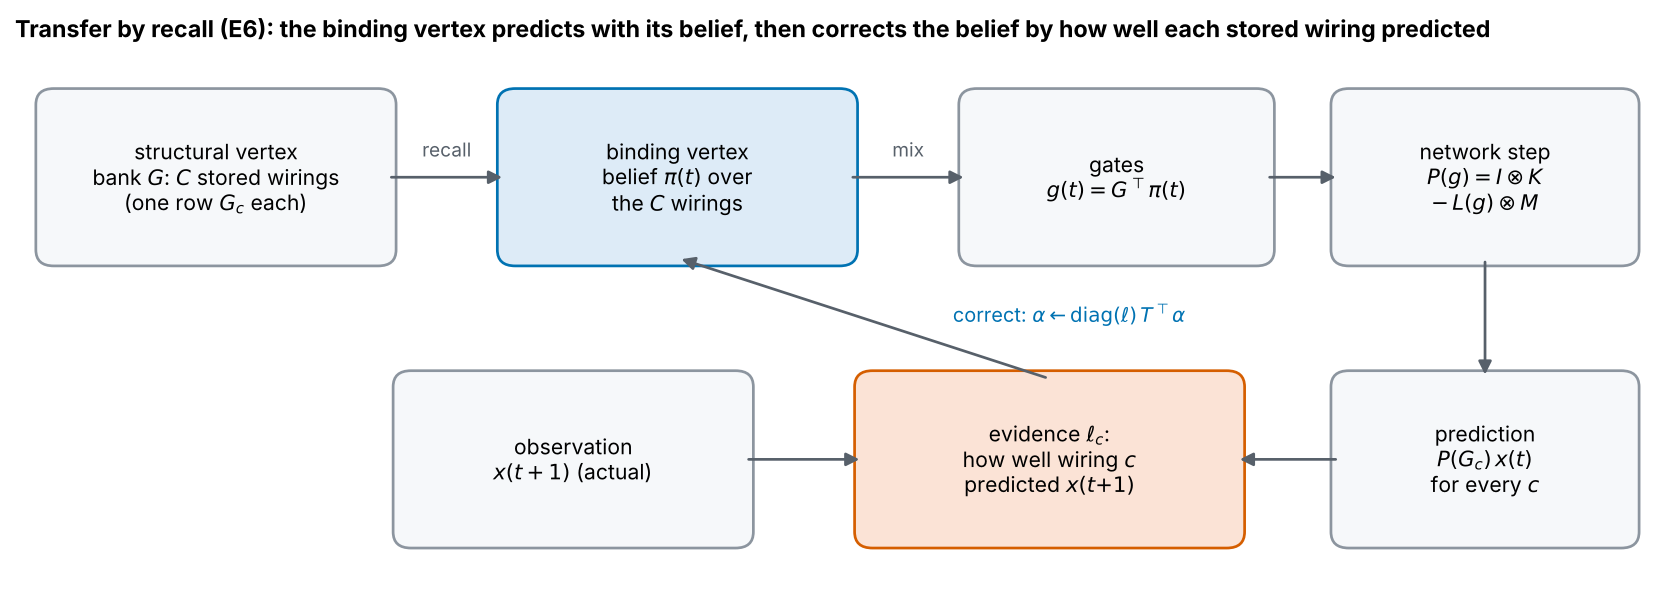

$$\underbrace{\alpha(t+1)}_{\text{unnormalised belief}}=\underbrace{\operatorname{diag}\big(\ell(t+1)\big)}_{\text{evidence}}\;\underbrace{T^\top}_{\text{persistence}}\;\alpha(t),\qquad\pi=\frac{\alpha}{\mathbf 1^\top\alpha},\qquad g(t)=G^\top\pi(t)$$

$$\ell_c(t+1)=\exp\!\Big(-\tfrac12\big\|x(t+1)-P(G_c)\,x(t)\big\|^2_{\Sigma^{-1}}\Big),\qquad T=(1-h)\,I+\frac{h}{C-1}\big(\mathbf 1\mathbf 1^\top-I\big)$$

Here $h$ is the hazard (the chance per step that the wiring changes) and $\Sigma$ the diagonal covariance of one-step residuals, measured on a stretch with known gates. This is the forward pass of a hidden Markov model (Rabiner, *Proc. IEEE* 1989), the same machinery as the COIN model of motor memory (Heald, Lengyel & Wolpert, *Nature* 2021), and the minimal form of the Tolman-Eichenbaum-style binding proposed for the end of step 1 (Whittington et al., *Cell* 2020): binding a context to stored structure, without yet learning the structure itself. Unnormalised, it is a linear predictor $T^\top$ whose output is gated element by element by evidence: the same algebra as a gated edge of the network, which is why it can live as one more vertex.

The persistence matrix is a prior over how wirings change. The default spreads $h$ evenly over every other stored wiring; E7 also tries one that expects a single spring to flip, spreading $h$ over the wirings one gate away. It helps when changes really are single flips and hurts when whole patterns change, so the right $T$ depends on the world.

**Recall** over a window picks $\hat c=\arg\min_c\sum_t\mathrm{NLL}_c(t)$, with $\mathrm{NLL}_c=-\log\ell_c$.

**Is this wiring new?** Compare the best stored wiring with one detected (Part 9) on the same window:

$$\Lambda=\min_c\sum_t\mathrm{NLL}_c(t)-\sum_t\mathrm{NLL}_{\hat g}(t)\;>\;\tau\quad\Longrightarrow\quad\text{store }\hat g\text{ as a new row of }G$$

with $\tau$ set so that 1% of windows from stored wirings exceed it. Both terms carry the same noise energy (about $\tfrac12$ per coordinate per step), so the difference cancels it; an absolute test on $\min_c\sum_t\mathrm{NLL}_c$ alone has to set its threshold above that noise.

**In the library**, `src/nsp/context.py`: `ContextBank` (lines 27–42), `residual_scale` (lines 45–49), `uniform_transitions` (lines 52–54), `flip_transitions` (lines 57–62), `BindingVertex` (lines 65–106).

```python
@dataclass
class ContextBank:
    """Stored structures over a fixed edge list."""

    n: int
    edges: list[Edge]
    patterns: np.ndarray = field(default_factory=lambda: np.zeros((0, 0)))

    def laplacians(self) -> list[np.ndarray]:
        return [laplacian(self.n, self.edges, p) for p in self.patterns]

    def append(self, pattern) -> int:
        """Store a new structure; returns its index."""
        p = np.asarray(pattern, float)[None]
        self.patterns = p if self.patterns.size == 0 else np.vstack([self.patterns, p])
        return len(self.patterns) - 1

def residual_scale(X: np.ndarray, P: np.ndarray, d: int = 1) -> np.ndarray:
    """Per-coordinate residual standard deviation (positions, rates), tiled over bodies. X: (ntraj, T + 1, N)."""
    R = (X[:, 1:] - X[:, :-1] @ P.T).reshape(-1, X.shape[-1] // (2 * d), 2 * d)
    s = np.r_[np.full(d, R[..., :d].std()), np.full(d, R[..., d:].std())]
    return np.tile(s, X.shape[-1] // (2 * d))

def uniform_transitions(C: int, hazard: float) -> np.ndarray:
    """Stay with probability 1 - h; otherwise jump to any other stored structure, all equally likely."""
    return (1 - hazard) * np.eye(C) + hazard / max(C - 1, 1) * (1 - np.eye(C))

def flip_transitions(patterns: np.ndarray, hazard: float) -> np.ndarray:
    """Stay with probability 1 - h; otherwise flip exactly one spring (structures one gate apart, all equally likely)."""
    G = np.asarray(patterns) > 0.5
    one_apart = (G[:, None, :] != G[None, :, :]).sum(-1) == 1
    T = one_apart / np.maximum(one_apart.sum(1, keepdims=True), 1) * hazard
    return T + (1 - hazard) * np.eye(len(G))

class BindingVertex:
    """Belief over the bank's stored structures, filtered step by step.

    `transitions` is the prior over how structures change, T[c, c'] = P(c' next | c now); the default is uniform jumps.
    """

    def __init__(self, bank: ContextBank, model: OneHop, scale: np.ndarray, hazard: float = 0.01,
                 transitions: np.ndarray | None = None):
        self.bank, self.model, self.scale, self.hazard = bank, model, np.asarray(scale), hazard
        self.P = np.array([model.assemble(L) for L in bank.laplacians()])
        C = len(self.P)
        self.T = uniform_transitions(C, hazard) if transitions is None else np.asarray(transitions)

    def nll_steps(self, X: np.ndarray) -> np.ndarray:
        """Per-step negative log-likelihood (up to a constant) of each stored context. X: (T + 1, N) -> (T, C)."""
        R = X[None, 1:] - np.einsum("cij,tj->cti", self.P, X[:-1])
        return 0.5 * ((R / self.scale) ** 2).sum(-1).T

    def filter(self, X: np.ndarray, prior=None) -> np.ndarray:
        """Belief after each step, starting from a uniform prior. Returns (T, C)."""
        nl = self.nll_steps(X)
        C = nl.shape[1]
        pi = np.full(C, 1.0 / C) if prior is None else np.asarray(prior, float)
        out = np.empty_like(nl)
        for t in range(len(nl)):
            pi = np.exp(-(nl[t] - nl[t].min())) * (self.T.T @ pi)
            pi /= pi.sum()
            out[t] = pi
        return out

    def recall(self, X: np.ndarray) -> int:
        """The stored structure that best explains a window."""
        return int(np.argmin(self.nll_steps(X).sum(0)))

    def likelihood_ratio(self, X: np.ndarray, pairs: list[Edge]) -> float:
        """Lambda: best stored structure's NLL minus that of a structure detected on the same window."""
        best = self.nll_steps(X).sum(0).min()
        n, d = self.bank.n, self.model.K.shape[0] // 2
        g = detect_gates(X[None], self.model, pairs, n, d)
        P = self.model.assemble(laplacian(n, pairs, g))
        free = 0.5 * (((X[1:] - X[:-1] @ P.T) / self.scale) ** 2).sum()
        return float(best - free)
```

## 11 · Preview of stage 1.5: two angles per body

*In one sentence:* with two tilt angles per body, small swings are two independent copies of the planar problem, so everything above carries over with $\otimes I_2$; large swings need lifts that do not prefer a direction.

Order each body's state phase-major, $x_v=(q_x,q_y,\dot q_x,\dot q_y)$. Then $A_0\to A_0\otimes I_d$ and $E\to E\otimes I_d$, so for small swings

$$K=K_2\otimes I_d,\qquad M=M_2\otimes I_d\qquad(\text{still 8 learned numbers})$$

where $K_2,M_2$ are the planar maps. Springs pointing in different directions read only their own component, a restriction map $I_2\otimes n_e^\top$ with $n_e$ the spring's unit direction, and the planar $M$ transfers unchanged.

For large swings the lift must treat every direction alike, so it uses only rotation-invariant combinations: $q\|q\|^2,\ q\|\dot q\|^2,\ q\,(q\cdot\dot q),\ \dot q\|q\|^2,\ \dot q\|\dot q\|^2,\ \dot q\,(q\cdot\dot q)$. With $d=2$ that is 16 features instead of the 24 of a full cubic lift.

**In the library**, `src/nsp/model.py`: `OneHop.per_direction` (lines 76–79).

```python
def per_direction(self, d: int) -> "OneHop":
    """Apply a planar model once per direction: K (x) I_d, M (x) I_d (stage 1.5a)."""
    I = np.eye(d)
    return OneHop(np.kron(self.K, I), np.kron(self.M, I))
```

**In the library**, `src/nsp/fit.py`: `fit_kronecker` (lines 67–71).

```python
def fit_kronecker(datasets: list[Dataset], d: int):
    """K = K2 (x) I_d and M = M2 (x) I_d: 8 numbers whatever d (stage 1.5a)."""
    planar = [(Xk, L) for X, L in datasets for Xk in split_directions(X, d)]
    m, info = fit_joint(planar, 1)
    return m.per_direction(d), info
```

**In the library**, `src/nsp/lifts.py`: `invariant_features` (lines 38–44).

```python
def invariant_features(xv: np.ndarray) -> np.ndarray:
    """Rotation-invariant cubic lift for two tilts (d = 2, stage 1.5). xv: (N, 4) rows of (q, q')."""
    q, v = xv[:, :2], xv[:, 2:]
    qq = (q**2).sum(1, keepdims=True)
    vv = (v**2).sum(1, keepdims=True)
    qv = (q * v).sum(1, keepdims=True)
    return np.hstack([xv, q * qq, q * vv, q * qv, v * qq, v * vv, v * qv])
```

## 12 · Hidden information: a clamped sense (step 2)

*In one sentence:* when only angles are measured, each body predicts with step 1's maps and corrects itself through its clamped angle; that correction is where predictive-coding relaxation settles, and its stability splits per graph frequency.

Each body senses its angle with noise of standard deviation $s$; its rate is never measured:

$$\underbrace{y_v(t)}_{\text{clamped sense}}=\underbrace{c}_{[1,\;0]}\,x_v(t)+\varepsilon_v(t),\qquad\varepsilon_v\sim\mathcal N(0,s^2)$$

**The delay line** reads the rate off two readings, $\hat{\dot\theta}(t-1)=A_{\theta\dot\theta}^{-1}\big(y(t)-A_{\theta\theta}y(t-1)\big)\approx\big(y(t)-y(t-1)\big)/\Delta t$, so its rate noise is about $\sqrt2\,s/\Delta t$ at every step.

**The clamped sense.** Each body predicts, $\hat x^-_v=K\hat x_v-M\sum_u g_{uv}(\hat x_v-\hat x_u)$, then relaxes on an energy that weighs its sense against its prediction:

$$E_v(x)=\underbrace{\frac{(y_v-c\,x)^2}{2s^2}}_{\text{sense error}}+\underbrace{\tfrac12(x-\hat x^-_v)^{\top}\,\Pi^{-1}(x-\hat x^-_v)}_{\text{prediction error}}\quad\Longrightarrow\quad\hat x_v=\hat x^-_v+\underbrace{\frac{\Pi c^\top}{c\,\Pi c^\top+s^2}}_{k}\big(y_v-c\,\hat x^-_v\big)$$

$\Pi$ is the prior covariance: fixed at the lone body's steady state (from the Riccati equation, given $q$, the rate variance per step the body allows for unmodelled forces), or growing from a cold start through each body's own $2\times2$ Riccati recursion. Neither shares covariance between bodies.

**Stability per graph frequency.** The error obeys $e(t)=\big(I-(I_n\otimes k)C\big)P\,e(t-1)$, which splits by the spectrum identity into one block $(I-kc)(K-\lambda M)$ per graph frequency. When that block's eigenvalues are a complex pair, $|\mu|^2=\det$, so

$$\rho=\sqrt{(1-k_\theta)\,\det(K-\lambda M)}\approx\sqrt{1-k_\theta}\qquad(\det(K-\lambda M)\approx1\text{: the step nearly preserves area})$$

and every graph mode converges at the rate the angle gain sets.

**Why learning (H2) needs care.** With only $\theta$ sensed, $K\to TKT^{-1}$, $M\to TMT^{-1}$ with $T=\begin{bmatrix}1&0\\ \alpha&\beta\end{bmatrix}$ predicts the same angles, so the learned hidden coordinate can be any mix $\alpha\theta+\beta\dot\theta$; physics has to be read from eigenvalues, which do not change.

**Worked example** ($s$ = 1% of a 0.1 rad swing, $q=10^{-8}$): the steady gain is $k=\begin{bmatrix}0.04743 & 0.02297\end{bmatrix}^{\top}$, so $\rho=0.9760$ at $\lambda=0$ and $0.9760$ at $\lambda=4$, against $\sqrt{1-k_\theta}=0.9760$: the error halves every 28.5 steps. The delay line's rate noise is $\sqrt2\,s/\Delta t=0.0283$ rad/s, 14% of the rate scale $a\,\omega_0$.

**In the library**, `src/nsp/sense.py`: `observe` (lines 31–36), `lone_gain` (lines 44–48), `lone_gains` (lines 51–66), `relax` (lines 69–84), `clamped_filter` (lines 87–102), `delay_line` (lines 105–120), `mode_radius` (lines 147–150).

```python
def observe(world: World, X: np.ndarray, rel: float, amplitude: float, rng) -> np.ndarray:
    """Measured angles only: (..., n * 2) states -> (..., n) angles plus noise of rel x amplitude (planar)."""
    if world.d != 1:
        raise NotImplementedError("the clamped sense is planar for now")
    th = X[..., 0::2]
    return th + rng.normal(0.0, rel * amplitude, th.shape) if rel else th.copy()

def lone_gain(K: np.ndarray, s2: float, q: float):
    """Steady-state clamp gain k (2,) and prior covariance Pi (2, 2) for one body with sense noise s2 and rate noise q."""
    Pi = solve_discrete_are(K.T, C_ANGLE.T, process_noise(q), np.array([[s2]]))
    k = (Pi @ C_ANGLE.T / (C_ANGLE @ Pi @ C_ANGLE.T + s2)).ravel()
    return k, Pi

def lone_gains(K: np.ndarray, s2: float, q: float, v0: float, steps: int) -> np.ndarray:
    """Gain per step for one body whose prior precision grows from a cold start: the 2 x 2 Riccati recursion.

    Each body runs it alone (no covariance shared with neighbours), starting from angle variance s2 and rate variance
    v0^2; the gains fall from large (trust the sense) to the steady-state lone gain (trust the prediction).
    Returns (steps + 1, 2); row 0 is unused.
    """
    c = C_ANGLE
    S, Q = np.diag([s2, v0**2]), process_noise(q)
    ks = np.zeros((steps + 1, 2))
    for t in range(1, steps + 1):
        S = K @ S @ K.T + Q
        k = (S @ c.T / (c @ S @ c.T + s2)).ravel()
        S = (np.eye(2) - np.outer(k, c.ravel())) @ S
        ks[t] = k
    return ks

def relax(x_prior: np.ndarray, y: float, Pi: np.ndarray, s2: float, steps: int = 200, eta: float | None = None):
    """Gradient descent on one body's energy E(x), from x = x_prior. Returns the states and energies visited."""
    Pinv = np.linalg.inv(Pi)
    c = C_ANGLE.ravel()
    H = np.outer(c, c) / s2 + Pinv
    eta = 1.0 / np.linalg.eigvalsh(H).max() if eta is None else eta
    x = np.array(x_prior, float)
    xs, Es = [x.copy()], []
    for _ in range(steps):
        e_sense, e_prior = y - c @ x, x - x_prior
        Es.append(0.5 * e_sense**2 / s2 + 0.5 * e_prior @ Pinv @ e_prior)
        x = x - eta * (-c * e_sense / s2 + Pinv @ e_prior)
        xs.append(x.copy())
    e_sense, e_prior = y - c @ x, x - x_prior
    Es.append(0.5 * e_sense**2 / s2 + 0.5 * e_prior @ Pinv @ e_prior)
    return np.array(xs), np.array(Es)

def clamped_filter(model: OneHop, L: np.ndarray, Y: np.ndarray, k: np.ndarray) -> np.ndarray:
    """Local clamped-sense filter for one run. Y: (T + 1, n) measured angles. Returns estimates (T + 1, 2n).

    k is one gain (2,) for every step, or one per step (T + 1, 2) as from `lone_gains`. Cold start: angles from the
    first reading, rates zero.
    """
    P = model.assemble(L)
    n = Y.shape[1]
    ks = np.broadcast_to(np.asarray(k, float), (len(Y), 2)) if np.ndim(k) == 1 else np.asarray(k, float)
    Xh = np.zeros((len(Y), 2 * n))
    Xh[0, 0::2] = Y[0]
    for t in range(1, len(Y)):
        x = P @ Xh[t - 1]
        x += np.tile(ks[t], n) * np.repeat(Y[t] - x[0::2], 2)
        Xh[t] = x
    return Xh

def delay_line(model: OneHop, L: np.ndarray, Y: np.ndarray) -> np.ndarray:
    """The last two readings determine the state: solve theta(t) = A_tt y(t-1) + A_tv v(t-1) for the rate.

    Exact for the linear model on clean data; on noisy data it differentiates the noise. Returns (T + 1, 2n).
    """
    P = model.assemble(L)
    n = Y.shape[1]
    Att, Atv = P[0::2, 0::2], P[0::2, 1::2]
    Xh = np.zeros((len(Y), 2 * n))
    Xh[0, 0::2] = Y[0]
    for t in range(1, len(Y)):
        v = np.linalg.solve(Atv, Y[t] - Att @ Y[t - 1])
        prev = np.empty(2 * n)
        prev[0::2], prev[1::2] = Y[t - 1], v
        Xh[t] = P @ prev
    return Xh

def mode_radius(model: OneHop, k: np.ndarray, lams) -> np.ndarray:
    """Spectral radius of the clamped error map (I - k c)(K - lambda M), one per graph frequency lambda."""
    A = np.eye(2) - np.outer(k, C_ANGLE.ravel())
    return np.array([np.abs(np.linalg.eigvals(A @ model.mode_block(lam))).max() for lam in np.atleast_1d(lams)])
```

## Where the truth lives: the tests

The equations above are explanations. These tests are what the code is held to (`python -m pytest`):

| Test | What it pins down |
| --- | --- |
| `test_closed_form.py::test_spectrum_identity` | spec(I⊗K − L⊗M) = ∪ spec(K − λM), on a random gated ring of 8 (Part 4) |
| `test_closed_form.py::test_K0_closed_form` | K₀ = e^{A₀Δt} equals the cos/sin matrix (Part 1) |
| `test_closed_form.py::test_M0_series_to_dt_cubed` | the Fréchet-derivative M₀ matches the closed form to O(Δt⁴) (Part 5) |
| `test_closed_form.py::test_two_hop_term_is_what_one_hop_misses` | exact step − one-hop model = L²⊗N₀ to 2·10⁻⁵, for a path, ring and star (Part 5) |
| `test_closed_form.py::test_growth_and_frequency_formulas` | per-step growth and frequency error of the series match their formulas (Part 5) |
| `test_closed_form.py::test_two_angles_small_swings_are_two_planar_copies` | with two angles, the exact step is the planar one ⊗ I₂ (Part 11) |
| `test_closed_form.py::test_complete_graph_two_frequencies` | a complete graph of 8 has only the graph frequencies 0 and 8 (Part 2) |
| `test_closed_form.py::test_mode_frequencies_match_exact_step` | ω_k = √(ω₀² + κλ_k), read off the exact step's eigenvalues (Part 3) |
| `test_closed_form.py::test_verlet_matches_exact_when_linear` | velocity Verlet agrees with the exact step on a linear world (Part 8) |
| `test_closed_form.py::test_expm_sanity` | the matrix exponential of zero is the identity |
| `test_fit_detect_context.py::test_joint_fit_recovers_series` | least squares on every gate pattern of a path of 3 recovers K₀ and M₀ (Part 6) |
| `test_fit_detect_context.py::test_frozen_K_is_exact` | K fitted on lone pendulums equals K₀ to 10⁻¹⁰ (Part 6) |
| `test_fit_detect_context.py::test_gradient_descent_reaches_closed_form` | gradient descent ends at the least-squares answer (Part 6) |
| `test_fit_detect_context.py::test_parameter_recovery` | ω₀² and κ read back from the fitted K and M (Part 6) |
| `test_fit_detect_context.py::test_kronecker_fit_two_angles` | the two-angle fit is the planar fit ⊗ I₂ (Part 11) |
| `test_fit_detect_context.py::test_detection_one_spring_needs_two_trajectories_or_nnls` | the blind spot exists with one trajectory; NNLS or three trajectories close it (Part 9) |
| `test_fit_detect_context.py::test_recall_and_relock` | the binding vertex recalls a stored structure and re-locks after a switch (Part 10) |
| `test_fit_detect_context.py::test_design_steps_stack_into_the_window_design` | per-step detection blocks stack into the window's design (Part 9, E7) |
| `test_fit_detect_context.py::test_transition_priors` | the uniform and one-flip priors over wiring changes are proper transition matrices (Part 10) |
| `test_sense.py::test_relaxation_settles_on_the_clamp` | gradient descent on a body's energy ends at the clamped estimate (Part 12) |
| `test_sense.py::test_mode_radius_matches_the_whole_error_map` | the clamp's per-mode spectral radius equals the whole network's (Part 12) |
| `test_sense.py::test_delay_line_is_exact_on_clean_data` | two readings determine the state when the model is the world (Part 12) |
| `test_sense.py::test_clamped_filter_and_kalman_converge_on_clean_data` | the clamped sense and the Kalman filter converge (Part 12) |
| `test_sense.py::test_growing_precision_settles_on_the_steady_gain_and_converges_fast` | growing precision ends at the steady gain, and converges faster from a cold start (Part 12) |

**Rebuild this notebook** after changing the library: `python tools/build_math_notebook.py --html`. The code blocks, the numbers and the diagrams follow the code; the prose does not, so read the diff of the prose when the math changes.